# 01 · Fund Decomposition: investable exposures vs residual performance

**Question.** How much of a fund's return could an investor have bought cheaply through
investable index exposures, and is what's left (the *residual*) skill, noise, or fees?

**Approach.**
1. Returns-based style analysis (Sharpe, 1992): a constrained regression of fund returns on
   11 investable index proxies with weights ≥ 0 that sum to 1, so the fit *is* a buyable
   replicating portfolio.
2. Rolling windows to track style drift.
3. **Out-of-sample** replication quality: fit on 36 months, hold weights fixed, measure tracking
   error over the next 12 months. Compared with unconstrained OLS.
4. Residual alpha with Newey–West t-statistics, then a **multiple-testing** view
   (Benjamini–Hochberg FDR and a Fama–French-style bootstrap of the cross-section) to separate
   skill from luck.

Every step is checked against the **known ground truth** of the simulated universe
(`pfquant.simulate`). Set `USE_REAL_DATA = True` to run the same code on real ETFs and mutual
funds from Yahoo Finance.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats as sps
from pfquant import make_universe, stats, plotting
from pfquant.decompose import decompose_universe
plotting.setup()
pd.set_option("display.float_format", "{:.3f}".format)

USE_REAL_DATA = False
if USE_REAL_DATA:
    from pfquant.real_data import load_real_universe
    uni = load_real_universe()
else:
    uni = make_universe()
R, F, funds = uni.fund_returns, uni.factor_returns, uni.funds
HAS_TRUTH = uni.true_weights is not None
print(f"{R.shape[1]} funds × {R.shape[0]} months ({R.index[0]:%Y-%m} to {R.index[-1]:%Y-%m}), "
      f"{F.shape[1]} investable factors")

644 funds × 240 months (2006-01 to 2025-12), 11 investable factors


## 1. The universe at a glance

vehicle                    ETF             MF          All
passive                 Active Passive Active Passive     
category                                                  
Commodities Broad            1       4     10       3   18
Conservative Allocation      1       5     11       1   18
Diversified EM               3      10     27       3   43
Foreign Large Blend          5      13     32       7   57
Global Equity                5      12     27       2   46
High Yield Bond              8      14     20       2   44
Intermediate Core Bond       5       9     30      10   54
Long Government              3       7     16       1   27
Moderate Allocation          3      11     25       8   47
Real Estate                  5       5     10       1   21
US Large Blend               5      28     52       8   93
US Large Growth              7      15     48       4   74
US Large Value               8      11     21       3   43
US Small Cap                 6      14     33       6   59
All                         65     158    362      59  644

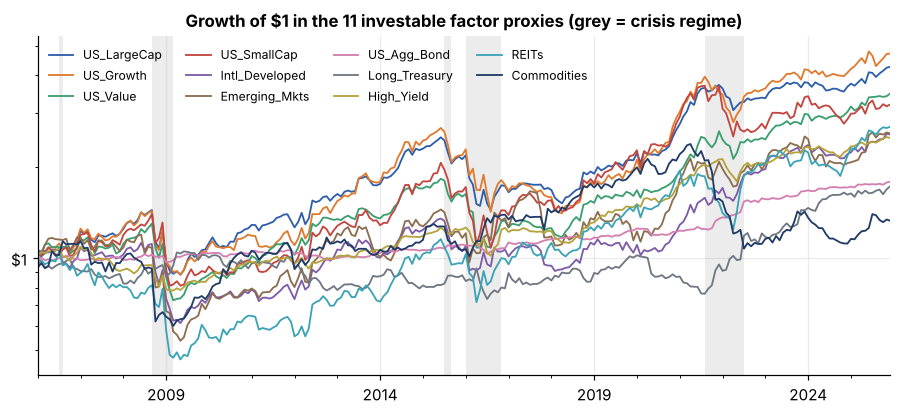

In [2]:
display(pd.crosstab(funds["category"], [funds["vehicle"], funds["passive"].map({True: "Passive", False: "Active"})],
                    margins=True))

fig, ax = plt.subplots(figsize=(10, 4))
(1 + F).cumprod().plot(ax=ax, logy=True, lw=1.2)
if uni.crisis is not None:
    for d, c in uni.crisis.items():
        if c: ax.axvspan(d - pd.offsets.MonthEnd(1), d, color="grey", alpha=0.15, lw=0)
ax.set_title("Growth of $1 in the 11 investable factor proxies (grey = crisis regime)")
ax.legend(ncol=4, fontsize=8, loc="upper left"); ax.set_xlabel("")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:g}")); ax.yaxis.set_minor_formatter(plt.NullFormatter())
plotting.save(fig, "01_factors")

## 2. Decomposing one fund: why the constraints matter

Unconstrained OLS treats the 11 factors as a free hedge basis. With highly correlated
equity factors it produces long/short weights that no advisor would hold and that do not sum
to 100 %. The constrained version returns an investable, interpretable portfolio.

In [3]:
full = R.columns[R.notna().all()]
cand = funds.loc[full]
cand = cand[(~cand["passive"]) & cand["category"].str.contains("Allocation|Global")]
example = (cand["true_te"] - cand["true_te"].median()).abs().idxmin() if HAS_TRUTH and len(cand) else full[0]
y = R[example].dropna(); X = F.loc[y.index]

w_rbsa, a_rbsa, res_rbsa, r2_rbsa = stats.rbsa(y.values, X.values)
Xc = np.column_stack([np.ones(len(X)), X.values])
b_ols = np.linalg.lstsq(Xc, y.values, rcond=None)[0]
r2_ols = 1 - (y.values - Xc @ b_ols).var() / y.var()

tbl = pd.DataFrame({"RBSA (constrained)": w_rbsa, "OLS (unconstrained)": b_ols[1:]}, index=F.columns)
if HAS_TRUTH:
    tbl.insert(0, "True average weight", uni.true_weights.loc[example])
tbl.loc["Sum of weights"] = tbl.sum()
print(f"Example fund {example}: {funds.loc[example, 'category']}, {funds.loc[example, 'vehicle']}, "
      f"expense ratio {funds.loc[example, 'expense_ratio']:.2%}")
print(f"R²  RBSA {r2_rbsa:.3f}   OLS {r2_ols:.3f}   |  alpha (ann.) RBSA {a_rbsa*12:.2%}   OLS {b_ols[0]*12:.2%}")
display(tbl.style.format("{:.1%}").background_gradient(cmap="RdBu", vmin=-0.6, vmax=0.6, axis=None))

Example fund F0102I: Moderate Allocation, MF, expense ratio 0.79%
R²  RBSA 0.864   OLS 0.866   |  alpha (ann.) RBSA 0.09%   OLS 0.37%


,True average weight,RBSA (constrained),OLS (unconstrained)
US_LargeCap,42.3%,44.6%,49.8%
US_Growth,1.4%,0.0%,-2.2%
US_Value,1.5%,0.0%,-3.7%
US_SmallCap,2.4%,4.1%,4.3%
Intl_Developed,12.0%,16.1%,16.5%
Emerging_Mkts,2.1%,0.0%,0.4%
US_Agg_Bond,27.0%,28.6%,15.3%
Long_Treasury,2.2%,0.0%,2.9%
High_Yield,4.0%,2.1%,1.5%
REITs,1.9%,1.1%,1.9%


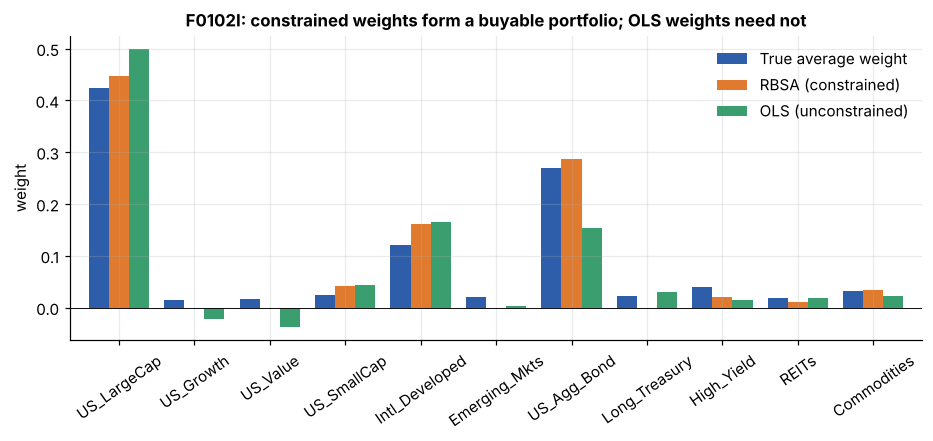

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.6))
plot_tbl = tbl.drop("Sum of weights")
plot_tbl.plot.bar(ax=ax, width=0.8)
ax.axhline(0, color="k", lw=0.6); ax.set_ylabel("weight")
ax.set_title(f"{example}: constrained weights form a buyable portfolio; OLS weights need not")
ax.tick_params(axis="x", rotation=35)
plotting.save(fig, "01_rbsa_vs_ols")

## 3. Style drift: rolling 36-month exposures

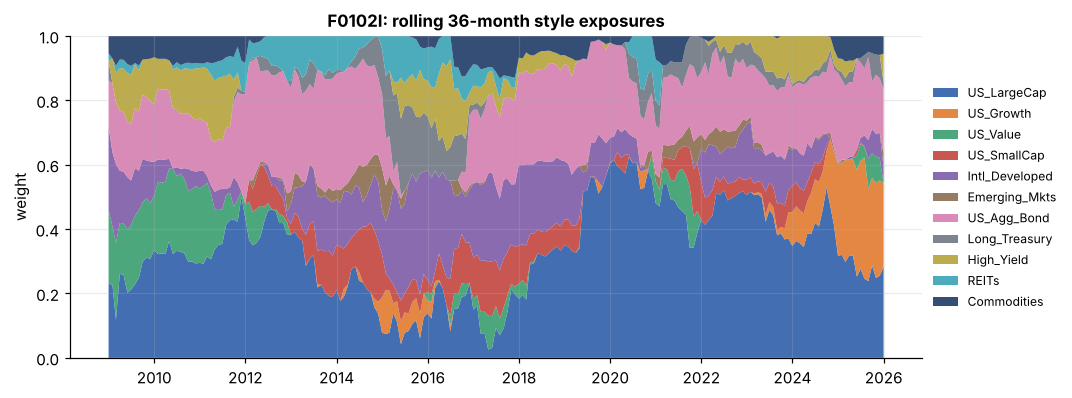

In [5]:
roll = stats.rolling_rbsa(y, X, window=36)
wcols = [c for c in F.columns if roll[c].max() > 0.03]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.stackplot(roll.index, roll[wcols].T.values, labels=wcols, alpha=0.9)
ax.set_ylim(0, 1); ax.set_ylabel("weight"); ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
ax.set_title(f"{example}: rolling 36-month style exposures")
plotting.save(fig, "01_style_drift")

## 4. Decomposing the whole universe

One RBSA per fund on its full history: style weights, annualised residual alpha (net of fees,
because fund returns are net), Newey–West t-stat, replication R² and tracking error.

,funds,median_R2,median_TE,mean_alpha,share_t_above_2
style,,,,,
Active,427,0.909,0.043,-0.007,0.040
Passive,217,0.999,0.004,-0.001,0.000


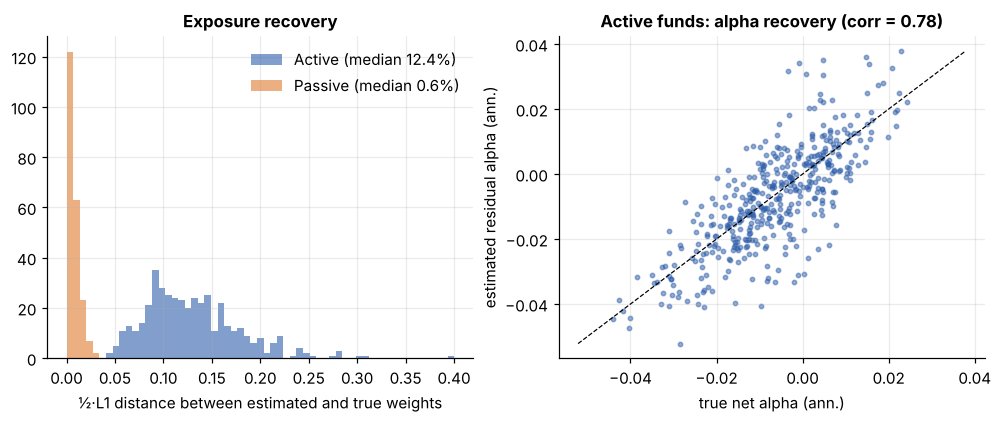

In [6]:
D = decompose_universe(R, F)
D = D.join(funds[["category", "vehicle", "passive", "expense_ratio", "portfolio_id"]])
D["style"] = np.where(D["passive"], "Passive", "Active")
summary = D.groupby("style").agg(funds=("r2", "size"), median_R2=("r2", "median"),
                                  median_TE=("te_ann", "median"), mean_alpha=("alpha_ann", "mean"),
                                  share_t_above_2=("t_alpha", lambda t: (t > 2).mean()))
display(summary)

if HAS_TRUTH:
    wcols = [f"w_{c}" for c in F.columns]
    est_w = D[wcols].to_numpy()
    true_w = uni.true_weights.loc[D.index].to_numpy()
    D["weight_error"] = 0.5 * np.abs(est_w - true_w).sum(1)       # share of the portfolio misallocated
    live = R.notna()
    D["true_net_alpha"] = (uni.true_alpha.where(live).mean() * 12 - funds["expense_ratio"]).loc[D.index]

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for s, g in D.groupby("style"):
        axes[0].hist(g["weight_error"], bins=np.linspace(0, 0.4, 60), alpha=0.6, label=f"{s} (median {g['weight_error'].median():.1%})")
    axes[0].set_xlabel("½·L1 distance between estimated and true weights"); axes[0].legend()
    axes[0].set_title("Exposure recovery")
    act = D[~D["passive"]]
    axes[1].scatter(act["true_net_alpha"], act["alpha_ann"], s=8, alpha=0.5)
    lim = [act[["true_net_alpha", "alpha_ann"]].min().min(), act[["true_net_alpha", "alpha_ann"]].max().max()]
    axes[1].plot(lim, lim, "k--", lw=0.8)
    rho = np.corrcoef(act["true_net_alpha"], act["alpha_ann"])[0, 1]
    axes[1].set_xlabel("true net alpha (ann.)"); axes[1].set_ylabel("estimated residual alpha (ann.)")
    axes[1].set_title(f"Active funds: alpha recovery (corr = {rho:.2f})")
    plotting.save(fig, "01_recovery")

## 5. Out-of-sample replication quality

In-sample R² flatters every model. What an allocator cares about is whether a replicating
portfolio built *today* keeps tracking the fund *tomorrow*. Walk forward through the sample:
each December, fit on the trailing 36 months, freeze the weights, and measure tracking error
over the next 12 months.

In [7]:
def ols_fit(y, X):
    Xc = np.column_stack([np.ones(len(X)), X])
    b = np.linalg.lstsq(Xc, y, rcond=None)[0]
    return b[1:], b[0]

anchors = [i for i in range(36, len(R) - 12 + 1, 12)]
rows = []
Fv = F.to_numpy()
for a in anchors:
    fit, test = slice(a - 36, a), slice(a, a + 12)
    for f in R.columns:
        yv = R[f].to_numpy()
        if np.isnan(yv[fit]).any() or np.isnan(yv[test]).any():
            continue
        w_c, al_c, res_c, _ = stats.rbsa(yv[fit], Fv[fit])
        w_o, al_o = ols_fit(yv[fit], Fv[fit])
        for name, w, al in (("RBSA", w_c, al_c), ("OLS", w_o, al_o)):
            is_res = yv[fit] - Fv[fit] @ w
            oos_res = yv[test] - Fv[test] @ w
            rows.append(dict(anchor=R.index[a - 1], fund=f, method=name,
                             te_is=is_res.std() * np.sqrt(12), te_oos=oos_res.std() * np.sqrt(12)))
oos = pd.DataFrame(rows).merge(D[["style"]], left_on="fund", right_index=True)
oos["ratio"] = oos["te_oos"] / oos["te_is"]
tab = oos.groupby(["style", "method"])[["te_is", "te_oos", "ratio"]].median().unstack("method")
tab.columns = [f"{a} · {b}" for a, b in tab.columns]
display(tab.rename(columns=lambda c: c.replace("te_is", "median in-sample TE").replace("te_oos", "median OOS TE")
                   .replace("ratio", "median OOS/IS ratio")))
pw = oos.pivot_table(index=["anchor", "fund"], columns="method", values="te_oos")
print(f"{len(anchors)} walk-forward windows, {len(pw):,} fund-years. "
      f"Constrained replication has lower OOS tracking error in {(pw['RBSA'] < pw['OLS']).mean():.0%} of fund-years.")

,median in-sample TE · OLS,median in-sample TE · RBSA,median OOS TE · OLS,median OOS TE · RBSA,median OOS/IS ratio · OLS,median OOS/IS ratio · RBSA
style,,,,,,
Active,0.033,0.037,0.046,0.041,1.383,1.094
Passive,0.003,0.003,0.004,0.004,1.389,1.049


17 walk-forward windows, 9,440 fund-years. Constrained replication has lower OOS tracking error in 80% of fund-years.


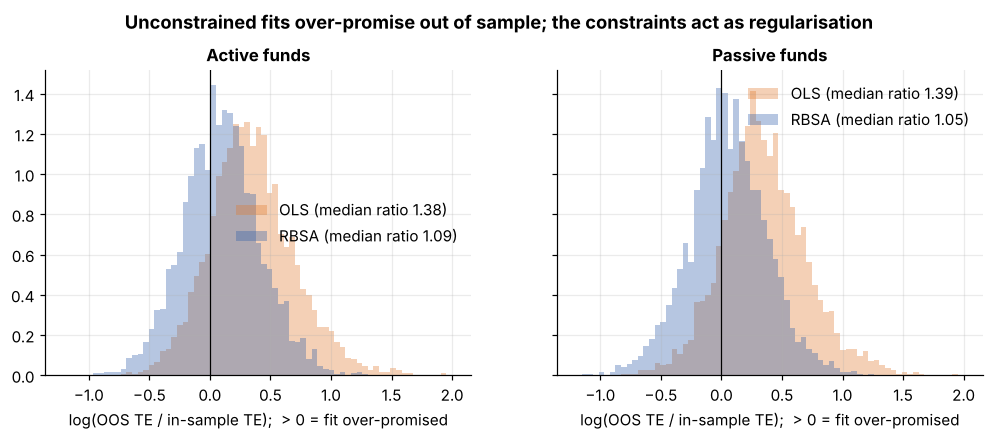

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
bins = np.linspace(-1.2, 2.0, 70)
for ax, style in zip(axes, ["Active", "Passive"]):
    for method, col in (("OLS", plotting.PALETTE[1]), ("RBSA", plotting.PALETTE[0])):
        g = oos[(oos["style"] == style) & (oos["method"] == method)]
        ax.hist(np.log(g["ratio"]), bins=bins, density=True, histtype="stepfilled", alpha=0.35, color=col,
                label=f"{method} (median ratio {g['ratio'].median():.2f})")
    ax.axvline(0, color="k", lw=0.8); ax.set_title(f"{style} funds"); ax.legend()
    ax.set_xlabel("log(OOS TE / in-sample TE);  > 0 = fit over-promised")
fig.suptitle("Unconstrained fits over-promise out of sample; the constraints act as regularisation",
             fontweight="bold", y=1.03)
plotting.save(fig, "01_oos_te")

## 6. Skill or luck? Residual alpha under multiple testing

With hundreds of active funds, some will show |t| > 2 by chance. Two complementary checks:

* **Benjamini–Hochberg** at a 10 % false-discovery rate on one-sided p-values (alpha > 0).
* **Cross-sectional bootstrap** (Fama & French, 2010): remove each fund's alpha, resample *the
  same months for every fund* (keeping cross-correlation), recompute t-stats, and compare the
  actual cross-section of t-stats with the luck-only distribution.

In [9]:
act = D[~D["passive"]].copy()
act["p_one_sided"] = sps.t.sf(act["t_alpha"], df=act["n_obs"] - 1)
act["naive_t>2"] = act["t_alpha"] > 2
act["BH_10%"] = stats.bh_fdr(act["p_one_sided"].values, q=0.10)

res = {"naive t > 2": act["naive_t>2"], "Benjamini–Hochberg 10%": act["BH_10%"]}
out = []
for k, m in res.items():
    row = dict(rule=k, discoveries=int(m.sum()))
    if HAS_TRUTH:
        truly_pos = act["true_net_alpha"] > 0
        row["precision (true net alpha > 0)"] = truly_pos[m].mean() if m.any() else np.nan
        row["mean true net alpha of picks"] = act.loc[m, "true_net_alpha"].mean() if m.any() else np.nan
    out.append(row)
if HAS_TRUTH:
    out.append(dict(rule="all active funds (base rate)", discoveries=len(act),
                    **{"precision (true net alpha > 0)": (act["true_net_alpha"] > 0).mean(),
                       "mean true net alpha of picks": act["true_net_alpha"].mean()}))
display(pd.DataFrame(out).set_index("rule"))

,discoveries,precision (true net alpha > 0),mean true net alpha of picks
rule,,,
naive t > 2,17,0.882,0.013
Benjamini–Hochberg 10%,8,0.750,0.011
all active funds (base rate),427,0.326,-0.007


,actual t,"luck-only (mean of 1,000 sims)",% sims below actual
p1,-5.643,-2.251,0.000
p5,-4.179,-1.620,0.000
p10,-3.521,-1.268,0.000
p50,-0.838,-0.000,0.000
p90,1.087,1.278,0.106
p95,2.023,1.632,0.976
p99,3.260,2.257,0.996


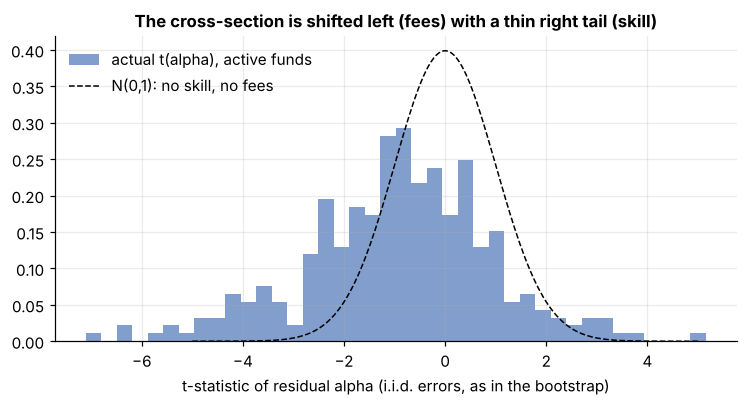

In [10]:
# Fama–French style bootstrap on funds with full history
full_act = [f for f in act.index if R[f].notna().all()]
Fv = F.to_numpy()
E = np.empty((len(R), len(full_act)))
for j, f in enumerate(full_act):
    w, a, resid, _ = stats.rbsa(R[f].values, Fv)
    E[:, j] = resid + a
E0 = E - E.mean(0)                         # impose zero alpha
rng = np.random.default_rng(0)
t_actual = E.mean(0) / (E.std(0, ddof=1) / np.sqrt(len(E)))
pcts = [1, 5, 10, 50, 90, 95, 99]
boot = []
for b in range(1000):
    idx = rng.integers(0, len(E0), len(E0))
    s = E0[idx]
    tb = s.mean(0) / (s.std(0, ddof=1) / np.sqrt(len(s)))
    boot.append(np.percentile(tb, pcts))
boot = np.array(boot)
ff = pd.DataFrame({"actual t": np.percentile(t_actual, pcts), "luck-only (mean of 1,000 sims)": boot.mean(0),
                   "% sims below actual": (boot < np.percentile(t_actual, pcts)).mean(0)},
                  index=[f"p{p}" for p in pcts])
display(ff)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(t_actual, bins=40, density=True, alpha=0.6, label="actual t(alpha), active funds")
xs = np.linspace(-5, 5, 200)
ax.plot(xs, sps.norm.pdf(xs), "k--", lw=1, label="N(0,1): no skill, no fees")
ax.set_xlabel("t-statistic of residual alpha (i.i.d. errors, as in the bootstrap)"); ax.legend()
ax.set_title("The cross-section is shifted left (fees) with a thin right tail (skill)")
plotting.save(fig, "01_t_distribution")

## 7. Summary

In [11]:
summary_numbers = {
    "Funds decomposed": len(D),
    "Median replication R², passive": D.loc[D.passive, "r2"].median(),
    "Median replication R², active": D.loc[~D.passive, "r2"].median(),
    "OOS fund-years where constrained beats OLS": (pw["RBSA"] < pw["OLS"]).mean(),
    "Active funds with t > 2": int(act["naive_t>2"].sum()),
    "BH-FDR 10% discoveries": int(act["BH_10%"].sum()),
}
if HAS_TRUTH:
    summary_numbers["Median exposure error, passive"] = D.loc[D.passive, "weight_error"].median()
    summary_numbers["Median exposure error, active"] = D.loc[~D.passive, "weight_error"].median()
    summary_numbers["Corr(estimated, true) net alpha, active"] = rho
    summary_numbers["Precision of naive t>2"] = act.loc[act["naive_t>2"], "true_net_alpha"].gt(0).mean()
    summary_numbers["Precision of BH-FDR"] = act.loc[act["BH_10%"], "true_net_alpha"].gt(0).mean()
pd.Series(summary_numbers).to_frame("value")

,value
Funds decomposed,644.000
"Median replication R², passive",0.999
"Median replication R², active",0.909
OOS fund-years where constrained beats OLS,0.800
Active funds with t > 2,17.000
BH-FDR 10% discoveries,8.000
"Median exposure error, passive",0.006
"Median exposure error, active",0.124
"Corr(estimated, true) net alpha, active",0.775
Precision of naive t>2,0.882


## Takeaways

* **Replication works, and its quality separates passive from active.** Median replication R² is
  0.999 for index funds and ≈0.91 for active funds; exposure recovery is within ≈1 % of the true
  weights for passive funds and ≈12 % for active funds, whose exposures drift.
* **Constraints are regularisation.** Unconstrained OLS fits slightly better in sample but its
  tracking error grows ≈38 % out of sample versus ≈9 % for the constrained replication, which wins
  in ≈80 % of walk-forward fund-years. For an allocator, the out-of-sample number is the one that matters.
* **Residual alpha is measurable but must be read under multiple testing.** Estimated alpha correlates
  ≈0.78 with the true net alpha. The cross-section of t-stats sits *left* of the luck-only
  distribution (fees), with a right tail (p95, p99) beyond luck in ≥97 % of bootstrap draws, i.e. a
  small set of genuinely skilled funds. Only a handful survive an FDR control, which is the honest
  size of the "pure alpha" shortlist.

**Limitations.** Real fund data adds survivorship bias, share-class duplication and benchmark
mismatch; the decomposition is only as good as the factor menu (11 proxies here). Notebook 03 tests
whether this residual alpha *persists*.